In [48]:
import pandas as pd
df = pd.read_csv("사회갈등의 정도 1순위.csv", encoding = 'cp949')
df

,구분,"개인,집단 간 상호이해 부족",이해당사자들의 각자 이익 추구,"개인,집단 간 가치관 차이",빈부격차,권력 집중,"기회의 불평등 (교육, 취업 등)",갈등 조정 기구 및 제도의 미비,기타
0,2022년,24.1,20.5,12.7,24.5,12.2,4.4,1.5,0.1
1,2023년,24.7,21.8,12.1,23.3,11.5,4.9,1.8,0
2,"동, 읍면부",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,도시(동부),24.9,22.2,11.6,23.6,11.1,4.9,1.6,0
4,농어촌(읍면부),23.5,19.4,14.6,21.7,13.4,5.0,2.4,-
5,성별,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,남자,23.9,22.1,12.5,22.9,11.5,5.0,2,0
7,여자,25.5,21.4,11.7,23.6,11.5,4.8,1.5,-
8,연령,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,19 ~ 29세,24.7,25.5,11.7,20.0,12.0,4.8,1.3,-


In [49]:
df.shape

(35, 9)

In [52]:
conflict = df.copy()

drop_list = list(range(0,9)) + list(range(11,14))+ list(range(15, len(conflict)))
conflict = conflict.drop(drop_list)

conflict

,구분,"개인,집단 간 상호이해 부족",이해당사자들의 각자 이익 추구,"개인,집단 간 가치관 차이",빈부격차,권력 집중,"기회의 불평등 (교육, 취업 등)",갈등 조정 기구 및 제도의 미비,기타
9,19 ~ 29세,24.7,25.5,11.7,20.0,12.0,4.8,1.3,-
10,30 ~ 39세,23.2,22.4,12.6,22.8,11.5,5.8,1.6,-
14,65세 이상,24.6,19.4,11.9,25.5,12.0,5.1,1.5,-


In [54]:
conflict.index = ['19~29세', '30~39세', '65세 이상']
conflict

,구분,"개인,집단 간 상호이해 부족",이해당사자들의 각자 이익 추구,"개인,집단 간 가치관 차이",빈부격차,권력 집중,"기회의 불평등 (교육, 취업 등)",갈등 조정 기구 및 제도의 미비,기타
19~29세,19 ~ 29세,24.7,25.5,11.7,20.0,12.0,4.8,1.3,-
30~39세,30 ~ 39세,23.2,22.4,12.6,22.8,11.5,5.8,1.6,-
65세 이상,65세 이상,24.6,19.4,11.9,25.5,12.0,5.1,1.5,-


In [56]:
conflict = conflict.drop(df.columns[0], axis = 1)
conflict

,"개인,집단 간 상호이해 부족",이해당사자들의 각자 이익 추구,"개인,집단 간 가치관 차이",빈부격차,권력 집중,"기회의 불평등 (교육, 취업 등)",갈등 조정 기구 및 제도의 미비,기타
19~29세,24.7,25.5,11.7,20.0,12.0,4.8,1.3,-
30~39세,23.2,22.4,12.6,22.8,11.5,5.8,1.6,-
65세 이상,24.6,19.4,11.9,25.5,12.0,5.1,1.5,-


In [58]:
conflict = conflict.drop(conflict.columns[7], axis = 1)
conflict

,"개인,집단 간 상호이해 부족",이해당사자들의 각자 이익 추구,"개인,집단 간 가치관 차이",빈부격차,권력 집중,"기회의 불평등 (교육, 취업 등)",갈등 조정 기구 및 제도의 미비
19~29세,24.7,25.5,11.7,20.0,12.0,4.8,1.3
30~39세,23.2,22.4,12.6,22.8,11.5,5.8,1.6
65세 이상,24.6,19.4,11.9,25.5,12.0,5.1,1.5


In [60]:
conflict.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3 entries, 19~29세 to 65세 이상
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   개인,집단 간 상호이해 부족     3 non-null      float64
 1   이해당사자들의 각자 이익 추구    3 non-null      float64
 2   개인,집단 간 가치관 차이      3 non-null      float64
 3   빈부격차                3 non-null      float64
 4   권력 집중               3 non-null      float64
 5   기회의 불평등 (교육, 취업 등)  3 non-null      float64
 6   갈등 조정 기구 및 제도의 미비   3 non-null      object 
dtypes: float64(6), object(1)
memory usage: 192.0+ bytes


In [62]:
# '갈등 조정 기구 및 제도의 미비'와 '기타' 열을 실수형으로 변환합니다.
conflict['갈등 조정 기구 및 제도의 미비'] = pd.to_numeric(conflict['갈등 조정 기구 및 제도의 미비'], errors='coerce')

In [64]:
# 인덱스가 연령대이므로 인덱스를 사용하여 19~29세와 30~39세의 행을 선택합니다.
conflict_young = conflict.loc[['19~29세', '30~39세']]

# 행의 평균을 계산합니다.
young_averages = conflict_young.mean()

# '청년'이라는 이름의 데이터프레임을 생성합니다.
young_df = pd.DataFrame([young_averages], index=['청년'], columns=conflict.columns)

# 원본 데이터프레임에 '청년' 행을 추가합니다.
conflict= pd.concat([conflict, young_df])

In [66]:
conflict

,"개인,집단 간 상호이해 부족",이해당사자들의 각자 이익 추구,"개인,집단 간 가치관 차이",빈부격차,권력 집중,"기회의 불평등 (교육, 취업 등)",갈등 조정 기구 및 제도의 미비
19~29세,24.70,25.50,11.70,20.0,12.00,4.8,1.30
30~39세,23.20,22.40,12.60,22.8,11.50,5.8,1.60
65세 이상,24.60,19.40,11.90,25.5,12.00,5.1,1.50
청년,23.95,23.95,12.15,21.4,11.75,5.3,1.45


In [68]:
conflict = conflict.drop(['19~29세'])
conflict = conflict.drop(['30~39세'])
conflict

,"개인,집단 간 상호이해 부족",이해당사자들의 각자 이익 추구,"개인,집단 간 가치관 차이",빈부격차,권력 집중,"기회의 불평등 (교육, 취업 등)",갈등 조정 기구 및 제도의 미비
65세 이상,24.60,19.40,11.90,25.5,12.00,5.1,1.50
청년,23.95,23.95,12.15,21.4,11.75,5.3,1.45


In [70]:
conflict = conflict.loc[['청년', '65세 이상']]
conflict

,"개인,집단 간 상호이해 부족",이해당사자들의 각자 이익 추구,"개인,집단 간 가치관 차이",빈부격차,권력 집중,"기회의 불평등 (교육, 취업 등)",갈등 조정 기구 및 제도의 미비
청년,23.95,23.95,12.15,21.4,11.75,5.3,1.45
65세 이상,24.60,19.40,11.90,25.5,12.00,5.1,1.50


In [76]:
# 새로운 열 순서 정의 및 변경
conflict = conflict.loc[:, [
    '개인,집단 간 상호이해 부족',
    '개인,집단 간 가치관 차이',  # 순서 변경
    '이해당사자들의 각자 이익 추구',  # 순서 변경
    '빈부격차',
    '권력 집중',
    '기회의 불평등 (교육, 취업 등)',
    '갈등 조정 기구 및 제도의 미비'
]]
conflict

,"개인,집단 간 상호이해 부족","개인,집단 간 가치관 차이",이해당사자들의 각자 이익 추구,빈부격차,권력 집중,"기회의 불평등 (교육, 취업 등)",갈등 조정 기구 및 제도의 미비
청년,23.95,12.15,23.95,21.4,11.75,5.3,1.45
65세 이상,24.60,11.90,19.40,25.5,12.00,5.1,1.50


In [92]:
conflict.T

,청년,65세 이상
"개인,집단 간 상호이해 부족",23.95,24.6
"개인,집단 간 가치관 차이",12.15,11.9
이해당사자들의 각자 이익 추구,23.95,19.4
빈부격차,21.40,25.5
권력 집중,11.75,12.0
"기회의 불평등 (교육, 취업 등)",5.30,5.1
갈등 조정 기구 및 제도의 미비,1.45,1.5


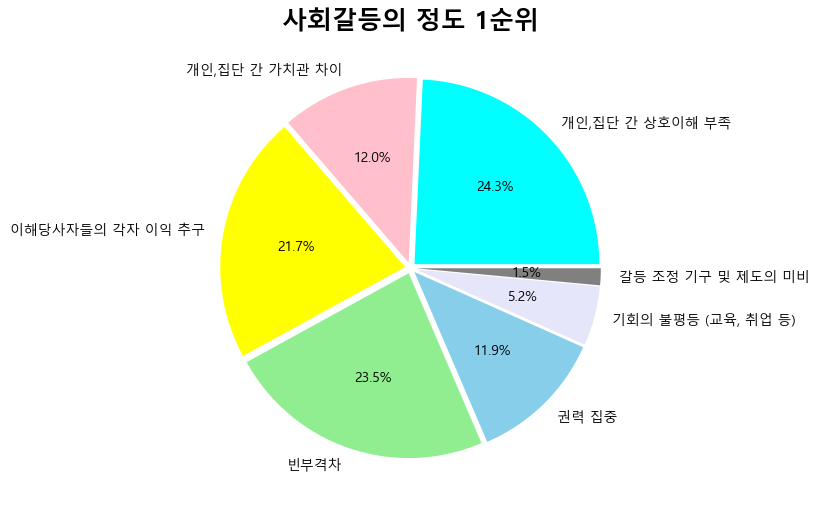

In [158]:
import matplotlib.pyplot as plt

# '청년'과 '65세 이상' 행의 평균 값 계산
data = conflict.loc[['청년', '65세 이상']].mean()


# 원형 그래프 생성
plt.rc('font', family='Malgun Gothic')
colors = ['aqua', 'pink', 'yellow', 'lightgreen', 'skyblue', 'lavender', 'gray']
explode = [0.03] * 7

plt.figure(figsize=(8, 6))
plt.title('사회갈등의 정도 1순위', size=18, weight = 'bold')
plt.pie(data, labels = data.index, autopct='%.1f%%', colors = colors, explode=explode)

# 그래프 표시
plt.show()
